# Land cover classification using sparse training data

## Table of Contents
* [Prerequisites](#Prerequisites)
* [Introduction](#Introduction)
* [Necessary imports](#Necessary-imports)
* [Connect to your GIS](#Connect-to-your-GIS)
* [Export training data](#Export-training-data)
* [Train the model](#Train-the-model)
 * [Prepare data](#Prepare-data)
 * [Visualize training data](#Visualize-training-data)
 * [Load model architecture](#Load-model-architecture)
 * [Find an optimal learning rate](#Find-an-optimal-learning-rate)
 * [Fit the model](#Fit-the-model)
 * [Accuracy assessment](#Accuracy-assessment)
 * [Visualize results in validation set](#Visualize-results-in-validation-set)
 * [Save the model](#Save-the-model)
* [Deployment and inference](#Deployment-and-inference)
* [Conclusion](#Conclusion)

## Prerequisites 

- Please refer to the prerequisites section in our [guide](https://developers.arcgis.com/python/guide/geospatial-deep-learning/) for more information. This sample demonstrates how to export training data and inference model using [ArcGIS Pro](https://www.esri.com/en-us/arcgis/products/arcgis-pro/overview). Alternatively, these can be done using [ArcGIS Image Server](https://www.esri.com/en-us/arcgis/products/arcgis-image-server) as well.
- If you have already exported training samples using ArcGIS Pro, you can jump straight to the training section. The saved model can also be imported into ArcGIS Pro directly.
- This notebook requires [ArcGIS API for Python](https://developers.arcgis.com/python/) version 1.8.1 or above.

## Introduction

This notebook showcases an approach to performing land cover classification using sparse training data and multispectral imagery. We will demostrate the utility of methods including the `imagery_type` and `ignore_classes` available in `arcgis.learn` module to perform training.

1) `imagery_type` parameter: The `prepare_data` function allows us to use imagery with any number of bands (4-band NAIP imagery in our case). This can be done by passing the imagery_type parameter. For more details, see [here](#Prepare-data).

2) `ignore_classes` parameter: The Segmentation or Pixel Classification model allows us to ignore one/more classes from the training data while training the model. We will ignore the 'NoData' class in order to train our model on sparse data.

The image below shows a subset of our training data.

<img src="data:image/PNG; base64, ...">


Note: The training data does not cover the whole image (which is a requirement in older version (v<1.8.1)), hence it is called sparse training data.

This notebook demonstrates capabilities of ArcGIS API for Python to classify a 4-band NAIP imagery given sparse training data.

## Necessary imports

In [1]:
import os
from pathlib import Path

from arcgis.gis import GIS
from arcgis.learn import prepare_data, UnetClassifier

## Connect to your GIS

In [2]:
# Connect to GIS
gis = GIS('home')

## Export training data 

We have labelled a few training polygons in the northern regions of Alabama state. The training data has the polygons labelled for six land cover classes namely 'buildings', 'roads and parking lots', 'water', 'harvested, open and bare lands', 'forest' and 'planted crops'. We need to classify NAIP imagery against these land cover classes. 

The feature class representing our labelled data contains an attribute field **classvalue** which represents the class of each labelled polygon. It is important to note here that all the pixels which are not labelled under any class will be mapped to 0, representing "NoData" class after exporting the data. 

This is how it looks:
<img src="data:image/PNG; base64, iVBORw0KGgoAAAANSUhEUgAAARUAAAC5CAIAAACJJTyUAAAAAXNSR0IArs4c6QAAAARnQU1BAACxjwv8YQUAAAAJcEhZcwAADsMAAA7DAcdvqGQAABl9SURBVHhe7Z1LbyPHdsebsb0xkI0TBwkpjUQ/Fk4u4sBZkMoFRtwY19shpQHED0FKM7b4GaixRkN+CA6gB7WdC29IAzckFzHiwIkXHpviSKMEceJNAOcCY4P3nKrq6mJ3VbNZoiQ2eX4gZtjNrq4H63SdU2L9K/H/f/yjQxCEFX8m/icIYnLIfgjCnin7bz/88MP3338vDq7Gu++++84774gDgphJpmw/X3zxxdf9b/7yvaQ4tuV/nl9+mP7Nxx9/LI4JYiaZvv28fO2nD373kTi25dvff5X69S2yH2LGofiHIOwh+yEIe8h+CMKeGNvPcHh+/OBerTsUxwrnRw8K+bx8PTw6Fx+Y6dbu5fFmeDd4b0oCd87Xuvy9moRYTOJqP9B3Nwrlp2cJcRxguL570mzC67i25TRKWjNTyZZPm6flbMJ4wyAWSYg5I5b2M+zW9lq5z05270Z49ieWNzdzTrvXE8cEMT1iaT+JbBke/BlxFIl0MgX/DsHy7j04PhdWNzw/ehjBZ4OPuB+Yf3D0UpxDZBLXk8R/8TIlC0BN3lXcPyiLOD96PREj5n/+gA9WmxtL4nhCoPfvDYpPTk7QG7x/+ejpmfggQLt64Oygx7ib6zcOwCKEWWqTg+l+Wh1s1dj5yho/ScSOubWfRHuPP9039trrlZJdlALjVa+VLu5sLLPkMO59tm4cKPh18CaTL6b7lzBSjUu+ssSMOpHd5AmJ2DG39uPNH5zUUod56TVNxsX5C7eXc1LJtHgX4M6yOsQNLi5Cky9l19KtR4XC2IkNYpaZf/8tkVgu7BTTrUObGOPlZV+8s8KcHEq18fj0uLb1ogrxD02Cx5X5tx+XkXFAMNY8cLxgI4nLZAY1LnliefPzZh2M++hYuYiID/NjP765NclweH5y0OjnMiwESqXS/UYT57Lh+nq1xa8xwea+vckAyOFRe5JABZ00fXJ4r3puo74fERvmaPwZDTa8+YNCubFSaZazeBJ8uf3KeqvKPupl4NHPrzaTKdWLTmO7UMAkvcyTrVXxQQRYdobkqSR4brx4nbV6OUvzB7FkftYvwBMdOii3k5kFhsijZH1/c1kcEzFnfsafi/PBemaiv6neNGDhV/lLFDGD0PrT6wUGHC/mGa7vNi3/EkXMJqR/QBD2TNl+CGKhWJy//xDE9CH7IQh7KP4hCHumP/929lX/vbfeE8e2PP/p+epHadKvImac6dvP62evffL+78SxLc+++/0vq7+S/RAzDsU/BGEP2Q9B2EP2QxD2xNJ+8Kei7LfV8NIuLO26kh38RWs8iWsifvaD63l6Sa7IcXyyu96qanVzVrdqfP02vK5vdQBYcv7BEV/eQywg8bMfXPlc3hSKHIksanV0utSDiVsh9vHP0vKKeBcBVdfX02ET6m3g9Hl6vPJKVZxN+o38JCTY2Gsnzp5uFwqW+iREzIm9/fR6LWdlmQ9H4YBJlBsrnwnHr1YcVNVO/+Kwl6o3uR4vXtlZE6JtlZVGqQ5GFVRsy5ZPj3fXh6tbcOWMr9sjrol42w909L1WbrekWTZ39rTsjhU4pAyH3WbDKdbF8htXlKfnCd+s5bkIm7jSFW1jam4tV/2XFNuIEWJsP+A+wXhiWpEm5w+ExHuv1/ZJ8Cwt31HEcTwFj17vS/DJykyxgOkTCJV6UmwjAsTSfnjEsudUrmn7g+Fwnbt58oXZkGIbESCW9tOrl6SkTlQCUmxBcVBB8EoFUmwjVOJnPxDHH7XSxbw/5jHpv3GEkhubCYBDLgrnFPPB4St45XEN/8IDt1c9N8/fY1LXxGIS0/inL+MT/sKebRpPXLLl01pxAAEMj2o6a0YdKbhyN4ehjrgymcW5BK1iG5tdgCtp/noxmZ/1C/jHmZnXfyPmjBjPv/mYff03Yv6g9acEYQ/pHxCEPVO2H4JYKOYn/iGIm4fshyDsofiHIOy5hvm3b75+72/eFse2PP/PH1d/8yHNvxEzzvTt5/X/vfzko78Tx7Y8++rff/mLJNkPMeNQ/EMQ9pD9EIQ9ZD8EYU8s7UfqeMBLK151fvQg+IPobu2e9uJZQ1t4qLIqlAV1kS1wAwJaMncom8wXXtfXniMVjPDbdrheLmq8yS86lvbT6zmuDMjunUZpZhdU+zq9Nbha6bC1fh8lGdgyp3t7g6KQN2k2d1ca5bxYrXQdqLnj4fouz/e4tuVcQ+Pjgiu2uJjnAq/d5PnYNsyWT69pMXI4sbSfbFm0VCKRzeSctqvuMbdcdDv9HP9xea9ebaeLtX1X3sRdrbRXv7ZGUHJXYQsNr6HxMbuR9ZHZTSH3N4PMQ/yTTqbEu8iAI/LwnvAQ5BDBn3xSCK4GLoHiOaBb5V4p3ZhJ1eG0CQG4WJx/cBRczco7MDwyYPDptRw5FEjYKr5DfkPuvXgZjQ6AwQK4tcZ/1fMSmbs4HkU2fpQm5YOkqREEqOvSf2lY0yvTYnLl2+G1Fgc3SLztBzrpXiu3uWFedGrgonu5VmdOyEmt6DTKysNbCsGVYGgbCM8B+kGv0+cdF75CO3U4bUI4D9+954/dv3z09AxOSoSeFn8eo4qQZijw9bmzp+Unzk6wdqYCAO3qgbPDnKVcv3EAvVqcH8l9FF/jR2lSMMKQMnC4puyXe4WgPWBas4LfrRDP+QMWA+BD6DBZM+hXJdp78kHFX4/a3mXLm2UwBXiDQnD3PTtBXCE4J5NZ73d6XCbE9WFEf5pcHc6UEM73Wml5PpEtf7Y+0p/QZtJrmUkeERCi8KXprswdDk2hJXd4CeANnlYVHQK5y4aF0XW94jV+lCYNL4NkefMxD64gF2lFIm2Igt9t8Lr4P1bAI6p8elqGNoWnfj4PjRpUMoA+5FvLDTZ3JN4i8DDblk/61S3xRhEGYcFV9ah7sbG8zMznPnxz0Nu/TJw55cJTfhGSuAv/oDpc6VGhfXf3REgj+GCycpqETLZB7aCo/3Mp3gM9MK+1uuhw0RhxaHFo6uAbUwEYnhwKwuSHWIsGc5cNC2PuycN8vucJIY1t0vAyqEBwtX+6Cc/Jjb1y/pLlyBT8dtVisqrJot4K8fbfUE2qAg5Hc6KHEDzJYPiSXgR4WeKDAJlMjonTM+fNdZus1eG0CZ2Xl33xuQY2OikOqklbC40wnRoXBuoLYMaf+yi+wS1ik05UBnhOQpPK0G4GmYf5g4nB3pbbdaewLs4H/LQG7sL1hPOGWKvDmRIGzqsGdXF82FZid6Gt1fR7PL1mA4ZH7iMBI4paUng1tORafLkbYDeP2KSTl8EL7YJpxyku3QDxsx941B0rPnG9imJw6FnhI1A3n6NHfBPgAT5pGAcA5sL1O4cdqRQnevDk6nCmhOK8G7LDfWScJiYtRqcLMqXKemskboZq+0TAIUThhVHbx1QAlkKDNncVuODkAOxWGtj4Jo1SBpzHU2qHNsymTIJpTQp+N0kc45+U0ykVnopWW5XBTyCQMAHfxHaxs8288OHqVq2SKx+Kj4KAC7fXGhR3vPvi31ucexDq8EO4wQZYbyr5opQvsO9ydau+76nDYVDEYwZtQryqVC8+LG2zoACurG0Nyjz+gajLKW6PdmAw6VKznnoIsbVogeF6pXk6Eumtbu2mDvOFPbxgmKs03eBQX3KTBelyB3D+QNyAZc2Cn+hNamoEDxhwWtWC9xCBthNzBpC2lnywXSjwj7CdDQp+N8b8rF+AJ/ec6b/hhEdy4i5ilyrItO4z38xP/DNn+m/geuHUV/Z2vPvbzT1G0PrTeYPGjZuE9A8Iwp4p2w9BLBQL+fcfgpgSZD8EYQ/FPwRhz/Tn377+tv/20lX3X/jx4vmHH9D+C8SsM337ufy/1z7IfiKObfm2+yz555Ptn0UQNw/FPwRhD9kPQdhD9kMQ9sTbfobdmlaDoquqhykXwPkbVpk4DxVzg09lOfnLoni4CgA1Oky/o54YtVSmtYB2TLH9tQ1788TYfnAFyGFLHARY3arx5Y0oZlF6ePUFjLLTi2NbeLGDcmrw4nJ20+2yE8FNUWp04KviTF2gap6Isf1cHB80VnLGhcIuSxs7xXS/051o0eN14kqRBOFre4rp6xRzCwWb1CmqkiwJprXH3xNB4mo/bJHjirroclJwnaNRr8wvhgaOx9TF3MTxKEK8xpWVCS0k5IOiaqqp8Y9ClNZ8adWBbogCN0KjS5xy0aYacfNG18OCk+ZlbRi0J2p/TnjD3gqxtB9o5ZODxp3KBNYzqi+DhOiVBcXQstch5mZCWegfRVRNvVevXpIDiKmEgCrIxs8gJnE5F7+Mm1mKzSRApzJR+8PJ8Ia9LWJpP9hLVioR/Qq8WOcvheiVGcXQXIQZBHTM+LIzed5SzA0VMwSRdOpceA/j0r6mEgoCaSPhk3EzS7FBUMcXILkfaQR0Jmr/8Q17S8TPfiCOx14ybuyBRyAf6/Fig8ai9DHANxOnGBoxNB9MxwxyEMkL5adn7P4BRRgcSxSYnFpW9GkTeBOPaIWEweEhqohIXWxTCRnB0TgKXiqp6SNBm/caKiBAp2eC9h/XsLdFzOwHPbfDFo9DWLfY470kOJUp59+ajzXq4/A8i6hXZmIKYm4m4CZsjJq8kCOmPqnam424lC0TVy20YW+RmNkPjPUbj09lhzg+2b2Lci8iJpkAfJ5Fk4DTYupqgfMhYm5aoGPVq+7s9iSFvHN/f2Sm3sIYUEJVIy6nIXjz0fFBL0CnMmn7hzbsLRLL+EcLe6SNTNeMQ3wfbCov2pcxbTE3H1CST/PVdk4N7SYo5PLmY2ZCWCpTCfmVWjAO2WficsqMGVShFvjLbPDmPik2rQAd/0hhgqqFNOztMj/243sEhgPfx3bREeHBgbNdyYkPQmAh+CN3/hp1zHJ4yKOLTlJENSjm5jS4e1noZZ5srbLEUDyUUwtOvI3o3JcuN8HhdMdSi0KCCfFSQfc1lTAE8QcoWX54HSa1k4UoxVYceDdfG1EsEQJ0zMGGx0FQzMSiasaGvVXmZ/0CPJNmWf8NBscFkcVZnJoC8zP+zLL+G7gxJKc2l9D6U2LKLNT4Q/oHBGHPlO2HIBaKOZp/I4gbh+yHIOyh+Icg7Jn+/NtZ/1/ef+8tcWzLd89/Wk3/I82/ETPO9O3njdf6n3xy1fnrZ8+ev/qV5q+JWYfiH4Kwh+yHIOwh+yEIe2JpP/hTUf7rYPYKLp7rKvpv2guuwnk05TEoJF8IoBbGJ4gRDi46QDEN//Vww2lpXOGtpto4Ell9uchUvsIl4KZYuxsgruOPKpum/c21vOD4ZHe9Vb1h2URcEqOIvE1XjC5bPvVLf9wU0irEsQFf9SfSuLvF2lkQS/uZaLloIpFFFYpOd+y3Pk0MIm8zJ0Z3Tcywxt10WZj4Z2VZrh5TPQrVewFXI6hIxpE+GJxX5XikJ+lzzMJF3gBtXq7DBrmhD6P2L/4Rf2zDx3w4da8fr5bWnVDtVttEcEOfCJ5d9YXgDtPr8VVZrR28UcuMbrPbULJ4Ml/1YnYPvBc/xIS8tLo2N+ViqpqPuNqPXLapVl4LWx7srfyEBjIJl5kUyaCJtcpjcOdPqwNwzfB8ZY2fBKDtw0Xe7iwvXUXYTZxymbpamqmJwLNSRfCsq4+M6hlo9egyGU/UCswMV78zhxCLF9C1Uy9m2kOJtqvW9fJSLJvXtrk2l6WLY23VgsTSfpY3H2PFsCEwttGakLcu+sDZbqJQBZwUX61BuEyrSAZJQpXHxIrxRHaTp0XMIm9SjM5a2E2cUpiuWlp4EwWYrPoePlErrR5dJrPe7/S4jbkOoSieWzVP1w4M0r2412vd3dpKK19fislp6dtclwtDV7UA8fbf0JmueGq3KjxmRQNTJWXGCZfBs41bnadIFpBVwEcnBwVrhNiAOMMIirxpxeg0eTHGCLsFmLJa2rgm8ohcfQ1YQg9flTnw5WZyIlb0HEKTrh0TD3r5kj87cpmN5TvcKkaNOdjm+lwMVQsS//gntGtwA2tXhVJMCNDuekUys1ASPMY2Hp8e17ZeVMFLRt8dTvLvzyfy5hOjM+ZlRNd9Q7gRcafo1dcAJRw7RjHnik38jEgXaXXtoDCZtTT6bGCZKN+IScGcLs4H3JhD2jyYi7ZqWuJvP2P7Chvij45ZBxx1uxH5qMY3OkWyQBJfhonlzc/ZhBLPIorImzEvHX5htyiMK3MYIU2kw6L60JU9jbtwuHPVU9yqYPFccMwYnMO1DjMYsIp27xhMQgxuIW0ezIXhq5qW+NkPzti4UmYshBXyYuwBo5kq4c4uj6yhRUKFy8QXw6YcRIcTSbSSbqPaaPA9iQBU/RKMaPIyoQq7iVPhMGdGW+axjGsiTwTPrvr4lfk17owI5+oQlb94AYLF83TtwM/sN/YaYD7MYMDSBp1Rk9C3ucxFOG+6qol3AV4X/8eLQWO78JS/vVvB4Rvfscek3iXAIagE/Smzv4HCZckH24UC/2R1SyhdwBezXexsl/G+KGlayZUP+SVMeexhiecIYVVta1C+ZB+kki9K+QJrcbxPNjE8R5G37XHmE5KXCRR2u7z3qNC+u3sy1jrxkbFfd7RlDoATLW78hYUxNxHCWhKKgeFlPmr1R7KAlM2mZ43jgGFkrzUo7njfKxRv18Gm4IdQ5A1uWmgGTnvguoXwEHEajdx9aXghbQ7VOip1ijtu0QPfLD8dZH7WL8Az49b132AEnE3pmZsp2MxWfyzYeQ6TphnOEOIf/7iARxvNcbouWOg8iyJv0Dn2osT0V2Nmqz8W9FEPI8wZ6qD1p/MJDAWK9Da4TPodXAjeUNhCVp4L6R8QhD1Tth+CWCjmJ/4hiJuH7Icg7KH4hyDsmf7827/9a/+v3n5fHNvy3z9+9/f/QPpVxKwzffv5r5ev/+Zvr7p/1jf/8eyvU7+Q/RAzDsU/BGEP2Q9B2EP2QxD2xNV+8IfrTDQDXlILgtMNaJrhmXHXEIQFsbQf/MHfw1Jnrc6XH/JFneIz9ot3dUU3XHwxcBy5xt09E/Jj02E0lTOCiKX9XBwfNFYqxt/J+5Yo4qr2dJotjhewM1xTgiCuQvzsB0aPMYsc2epLqVHIRCHub644UtBILr4fGgTBfCpngNSdkGpg3IFUhcv4lcRCEcPxh48ezjHv+kF5Oy4l4a4yZsaSTKFT52pE9XotLqeoFQTzqZzBGa3gGN7aIFxGLA4xnT/oNw6dbRb8aIUBlpZXXHlLd1GXK/PFzojgJ0yEzQWu1wuOcbTCZcTCEFP78cQBmaJ0QCEFrAUMCHq5J/+VSvEQiOmwSO/PJMLmYRIcY4QoSxCLQEztZwxcSuLF+QXKFDFXjTt1EAIx7y+ZYgNLRBE2reCY+IxYbGJoP2x6wJtMYwTHgRTquTabykwDd+qaOHfAVrpHFGEzC44RRPzsR4wkrqQozmUzsXI2nnhzCczKWm11npo5de0RjQuzCJs7/xAmOEYsPLH035ie4OBRAWOScmNFjCE+mUw0IAiUPJFY7tR5uuAoCOaIwObA2a7gZwI2SQD3l/sO7ObwkMc/naSNUAsxl8zP+gWU8Lpt/Tdi0Zif+YNb138jFhBaf0oQ9pD+AUHYM2X7IYiFYj7/fkoQNwPZD0HYQ/ZDEPaQ/RCEPWQ/BGEP2Q9B2EP2QxD2kP0QhD30+wOCsGf6v39rt1pvvPGGOLbl1atX67kc/f6NmHGm77+B8bx5Za5ugQRxA1D8QxD2kP0QhD1kPwRhzwLZT7d27+HRefC9Ba547y2oiFyx5MR0ofEnKrQpAxGE7Icg7JkT+wGvRnpT2l0VoiMVfTG5u/8C3D+4KQOKz7E9vHwa9hNt1gCn1J28IC0v89ha+PTu2PXenYNlAFCiyF+wbo0G1SsQe/vhHeUoWZeautpdFSICdys3VrhaLyYfVKUEnG9TBqBdPXB2MKPdXL9xAB0SeyHeYZLNGtSNIcBocGuW+yhnd9VaBMoABvZpdbBV4yfX+JWJRLa04zwBi1JsmIhOjO2HP6HLl/ehQ6h7aUXZVUGL2GqhXuL9G5OjNr23lZ0PLmIPb1BukemVijtMtFmDuzEEwvYq4iJcV62FvgyudmR2U5Yksby5f3p6kunBY4hmJiYllvbDXJd7KBraRC13cVZBei/GXRW09HptVcEUWFq+Yxa/HhXdZpdNvlkDU0UVu31x85Gjk3Ut9GVAQVZUUdVOGyayZXgMbTsHkORW5hVjSiztB72OZh28GohGfF82N60ouypcExabNYALBwZ0ruyrd8VaaMsA49jG49Pj2taLKsQ/IzEYIHJkvivtLhGduPpvvDdAz8j08CnrOR4Rd1XQEtxqwaepPRa7zRq4C9fznDebWry8FAL4oWUAb+1zePQoOya5ExW9DAzmtJHehMR+/gAie7CizcuSMhCJ3gM9w7+rQijBrRZO2N4OXpeSm0IasNusQbhwh52RvMbXAncEazQxsoHRo15t8bOmMsAAo47V3JnEhKXLTbIcW2JvPxywIu51QO8x7qoQAbiP3NkBt1pYq3szE6ObMpiw26wBXbi+IzdWiVILnFfYr6y3qngNjB4wqIhPDGVIJcFzk/USzQVxD1nOFZj++p9//sMf3nzzTXFsy88///xPv/0trf8hZpw5GX8I4laYvv28evUKRo8rAjcRtyOIGYb0DwjCHtp/gSDsofiHIOwh+yEIe8h+CMIesh+CsIfshyDsIfshCHvIfgjCHrIfgrCH7Icg7CH7IQhbHOdPa+QEwrFcNiEAAAAASUVORK5CYII=">


Training data can be exported by using the `Export Training Data For Deep Learning` tool available in [ArcGIS Pro](https://www.esri.com/en-us/arcgis/products/arcgis-pro/overview) as well as [ArcGIS Image Server](https://www.esri.com/en-us/arcgis/products/arcgis-image-server).

- `Input Raster`: NAIP imagery
- `Input Feature Class Or Classified Raster`: feature layer containing labeled polygons
- `Class Value Field`: field containing class values against each class
- `Tile Size X & Tile Size Y`: 256
- `Stride X & Stride Y`: 64
- `Meta Data Format`: 'Classified Tiles' as we are training an segmentation Model which in this case is `UnetClassifier`.
- `Environments`: Set optimum `Cell Size`, `Processing Extent`.

<img src="data:image/PNG; base64, ...">


The labels to export data using [Export training data](#Export-training-data) tool are available as a layer package.

<Item title:"land_cover_classification_sparse_training_data" type:Feature Layer Collection owner:api_data_owner>
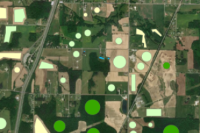

In [3]:
labels = gis.content.get('eeec636c856740c6a3e2c185dda6e735')
labels

## Train the model

We will be using U-Net, one of the well-recognized image segmentation algorithms, for our land cover classification. U-Net is designed like an auto-encoder. It has an encoding path (“contracting”) paired with a decoding path (“expanding”) which gives it the “U” shape. However, in contrast to the autoencoder, U-Net predicts a pixelwise segmentation map of the input image rather than classifying the input image as a whole. For each pixel in the original image, it asks the question: “To which class does this pixel belong?”. U-Net passes the feature maps from each level of the contracting path over to the analogous level in the expanding path. These are similar to residual connections in a `ResNet` type model, and allow the classifier to consider features at various scales and complexities to make its decision.

### Prepare data

We will specify the path to our training data and a few hyperparameters.

- `path`: path of the folder containing training data.
- `batch_size`: Number of images your model will train on each step inside an epoch, it directly depends on the memory of your graphic card. 8 worked for us on a 11GB GPU.
- `imagery_type`: It is a mandatory input to enable a model for multispectral data processing. It can be "landsat8", "sentinel2", "naip", "ms" or "multispectral".

<Item title:"land_cover_classification_using_sparse_training_data" type:Image Collection owner:api_data_owner>
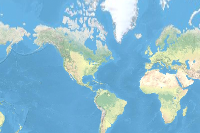

In [4]:
training_data = gis.content.get('08ccd71f862940bda1d8350c8cc91a47')
training_data

In [5]:
filepath = training_data.download(file_name=training_data.name)

In [6]:
import zipfile
with zipfile.ZipFile(filepath, 'r') as zip_ref:
    zip_ref.extractall(Path(filepath).parent)

In [7]:
data_path = Path(os.path.join(os.path.splitext(filepath)[0]))

In [8]:
data = prepare_data(data_path, batch_size=8, imagery_type='naip')

### Visualize training data

To get a sense of what the training data looks like, `arcgis.learn.show_batch()` method randomly picks a few training chips and visualizes them.
- `rows`: Number of rows to visualize.

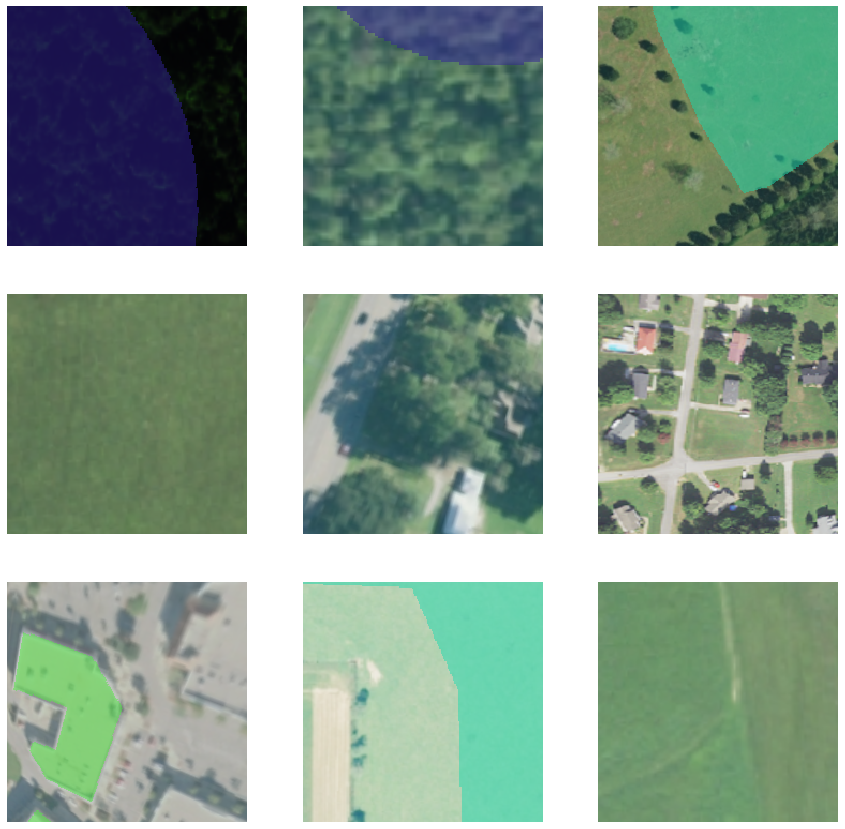

In [9]:
data.show_batch(rows=3)

### Load model architecture

As we now know, the 'NoData' class is mapped to '0' and we want to train our model on the six classes we had labeled, so we can put the 'NoData' class in `ignore_classes` parameter while creating a U-Net model. This parameter allows the model to skip all the pixels belonging to the mentioned class/classes, in other words model will not get trained on that class/classes.

In [10]:
# Create U-Net Model
unet = UnetClassifier(data, backbone='resnet34', ignore_classes=[0])

### Find an optimal learning rate

[Learning rate](https://en.wikipedia.org/wiki/Stochastic_gradient_descent) is one of the most important hyperparameters in model training. ArcGIS API for Python provides a learning rate finder that automatically chooses the optimal learning rate for you.

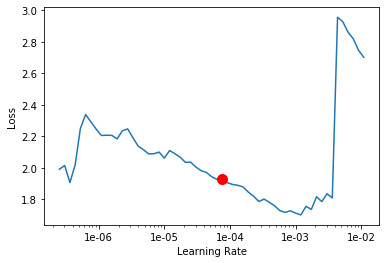

7.585775750291836e-05

In [11]:
unet.lr_find()

### Fit the model 

We will train the model for a few epochs with the learning rate we have found. For the sake of time, we can start with 10 epochs.

In [12]:
unet.fit(10, 7.585775750291836e-05)

epoch,train_loss,valid_loss,accuracy,time
0,0.204858,0.139798,0.951742,15:52
1,0.217454,0.129437,0.962800,15:55
2,0.180911,0.104669,0.971880,16:39
3,0.112541,0.087013,0.977520,16:04
4,0.189810,0.090733,0.973566,15:49
5,0.117280,0.081267,0.976252,15:48
6,0.111068,0.069316,0.981466,15:47
7,0.113275,0.090214,0.980469,15:47
8,0.093983,0.070652,0.982660,15:49
9,0.070856,0.067359,0.984696,15:50


Here, with only 10 epochs, we can see reasonable results — both training and validation losses have gone down considerably, indicating that the model is learning to classify land cover classes.

### Accuracy assessment

As we have 6 different classes for this classification task, we need to do accuracy assessment for each of those. For that ArcGIS API for Python provides `per_class_metrics` function that will calculate precision and recall for each class.

In [13]:
unet.per_class_metrics()

,Buildings,Forest,Harvested/Open/Bare Soil,Planted/Darker Cropland,Roads/Parking Lots/Driveways,Water
precision,0.910002,0.998542,0.986803,0.975038,0.951258,0.991753
recall,0.950265,0.999001,0.971385,0.987470,0.935559,0.978942
f1_score,0.929698,0.998772,0.979033,0.981215,0.943344,0.985306


Here, we can see the precision and recall values for each of the 6 classes are high with the model trained for just 10 epochs.

### Visualize results in validation set

Its a good practice to see results of the model viz-a-viz ground truth. The code below picks random samples and shows us ground truth and model predictions, side by side. This enables us to preview the results of the model within the notebook.

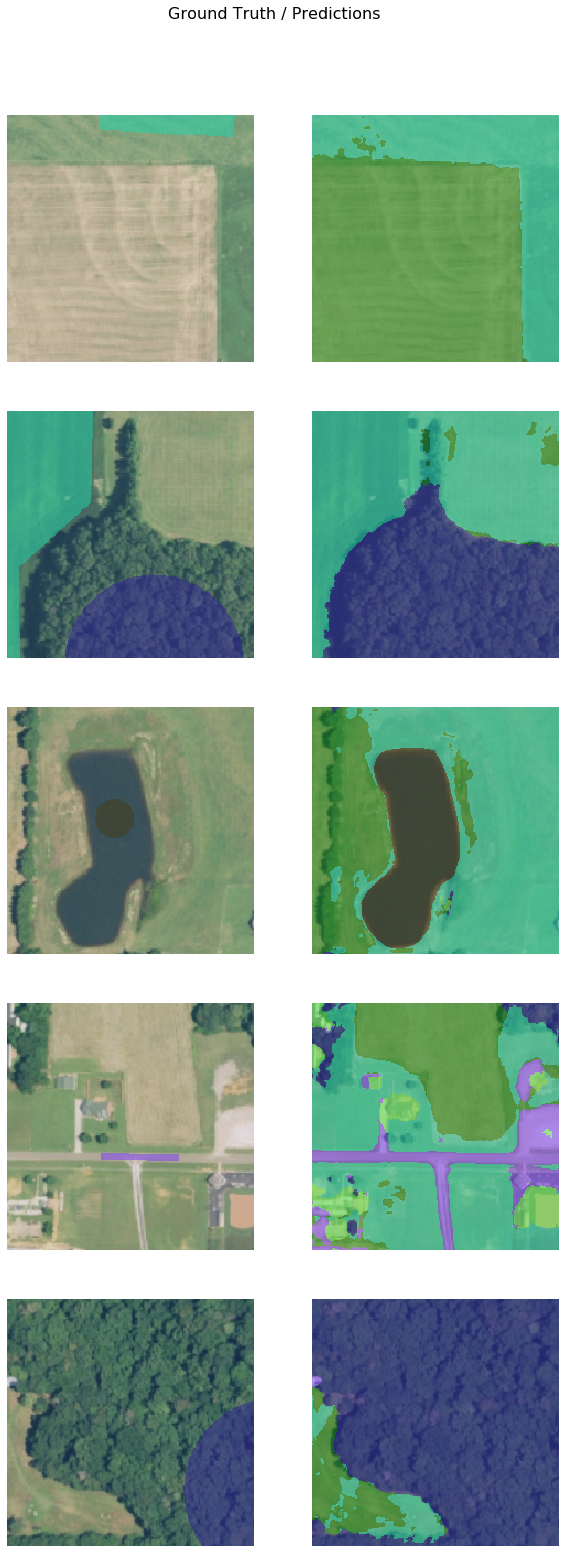

In [14]:
unet.show_results()

### Save the model

We will save the model which we trained as a 'Deep Learning Package' ('.dlpk' format). Deep Learning package is the standard format used to deploy deep learning models on the ArcGIS platform.

We will use the `save()` method to save the trained model. By default, it will be saved to the 'models' sub-folder within our training data folder.

In [15]:
unet.save('10e')

## Deployment and inference

In this step, we will generate a classified raster using 'Classify Pixels Using Deep Learning' tool available in both ArcGIS Pro and ArcGIS Enterprise.

- `Input Raster`: The raster layer you want to classify.
- `Model Definition`: It will be located inside the saved model in 'models' folder in '.emd' format.
- `Padding`: The 'Input Raster' is tiled and the deep learning model classifies each individual tile separately before producing the final 'Output Classified Raster'. This may lead to unwanted artifacts along the edges of each tile as the model has little context to predict accurately. Padding as the name suggests allows us to supply some extra information along the tile edges, this helps the model to predict better.
- `Cell Size`: Should be close to the size used to train the model. This was specified in the Export training data step.
- `Processor Type`: This allows you to control whether the system's 'GPU' or 'CPU' will be used to classify pixels, by 'default GPU' will be used if available.

<img src="data:image/PNG; base64, ...">


Output of this tool will be a classified raster. Here below, you can see the NAIP image and its classified raster using the model we trained earlier.  

<img src="data:image/PNG; base64, ...">


## Conclusion

This sample showcases how pixel classifcation models like UnetClassifier can be trained using sparsely labeled data. Additionally, the sample shows how you can use multispectral imagery containing more than just the RGB bands to train the model. 